In [2]:
import sys
sys.path[:0] = ["..", "../src"]

import numpy as np
import matplotlib.pyplot as plt
import config
import tools

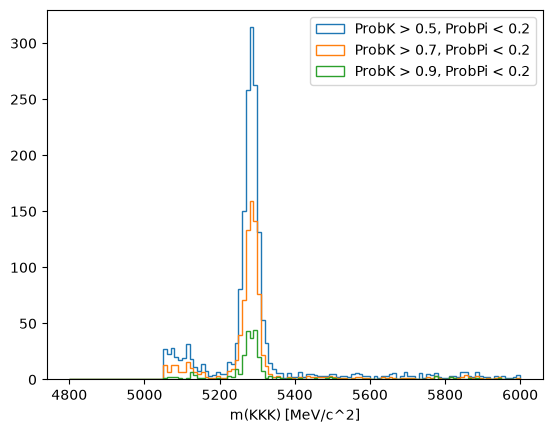

In [8]:
d = tools.load("down", entry_stop=1_000_000)

def mass_after_cuts(probk_min, probpi_max):
    steps = tools.cut_flow_masks(d, probk_min, probpi_max)
    keep = list(steps.values())[-1]
    sel = {k: v[keep] for k, v in d.items()}
    return tools.three_body_mass(sel)


fig, ax = plt.subplots()
for probk_min, probpi_max in [(0.5, 0.2), (0.7, 0.2), (0.9, 0.2)]: 
    m = mass_after_cuts(probk_min, probpi_max)
    ax.hist(m, bins=tools.mass_edges(), histtype="step",
        label=f"ProbK > {probk_min}, ProbPi < {probpi_max}")
ax.set_xlabel("m(KKK) [MeV/c^2]")
ax.legend()